<style>
.nb-body p, .nb-body li, .nb-body td, .nb-body th {
    font-family: Arial, Helvetica, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    text-align: justify;
    font-weight: normal;
    font-style: normal;
}
.nb-caption {
    font-family: Arial, Helvetica, sans-serif;
    font-size: 14px;
    line-height: 1.5;
    text-align: justify;
    margin-top: 6px;
    margin-bottom: 10px;
    font-weight: normal;
    font-style: normal;
}
</style>
<div class="nb-body">

# EODH Community Notebook Competition 2026

## Multi-Scale Satellite Flood Early-Warning and Parametric Risk Trigger across Kenya and Nigeria

### Description of Notebook

This notebook combines 26 years of daily satellite soil moisture data (0.25 degrees) with 10 m land cover and 10 m Sentinel-2 optical imagery from the EO Data Hub to show how regional catchment wetness connects to local flood inundation across Kenya and Nigeria.

* Author(s): Flawiya S. More
* Organisation / affiliation: University of Liverpool (MSc Geographic Data Science) / Environmental Data Scientist
* Language: Python
* Date: 2026-11-17

</div>

<div class="nb-body">

## 1. Purpose

Flood early-warning systems and disaster insurance programmes in Africa often rely on satellite climate datasets with coarse grid cells of 0.25 degrees (roughly 28 km by 28 km, or 770 sq km at the equator). While a 28 km grid cell is useful for tracking how wet a river basin is over many years, it is far too large to show whether floodwater is actually hitting a town or farmland. When a single average number is used for a 770 sq km area, vast stretches of dry bushland hide the flood risk in narrow river valleys. In disaster insurance, this mismatch between the satellite reading and actual damage on the ground is known as basis risk.

What the reader should learn: This notebook shows how to solve that scale mismatch using the EO Data Hub (EODH) and its Python client (pyeodh). By the end of the workflow, the reader will see how to combine coarse daily soil moisture records with 10 m land cover maps and 10 m Sentinel-2 flood imagery so that regional early-warning signals can be checked against real local exposure.

### Objectives

1. Build a 26-year daily baseline (2000-2026) of root-zone soil moisture and rainfall across Kenya and Nigeria using the EODH EOCIS dataset, and express daily wetness as a seasonal Z-score.
2. Open a 10 m Copernicus Land Cover map directly from the cloud to measure how much of a 28 km grid cell is urban settlement or farmland versus uninhabited bushland.
3. Map actual floodwater at 10 m resolution during the May 2024 Kenya flood disaster using Sentinel-2 imagery and compare it against the coarse soil moisture signal.
4. Test the early-warning trigger against 62 historical flood disasters from the Dartmouth Flood Observatory (DFO) to compare performance in local rainfall catchments (Kenya) versus large cross-border river systems (Nigeria).

### Expected outputs

The workflow produces four multi-panel figures (Figure 1 to Figure 4) and five summary tables (Table 1 to Table 5). Together, these outputs provide seasonal climate baselines, sub-pixel land cover breakdowns, 10 m flood extent maps, historical validation scores, and a practical alert matrix for disaster response teams.

</div>

<div class="nb-body">

## 2. Background and approach

### Workflow overview

The analysis is broken into small, step-by-step stages so that each intermediate result can be inspected before moving to the next stage:

1. Connect to the public EODH STAC catalogue using pyeodh and confirm access to the soil moisture, land cover, and Sentinel-2 collections (Table 1).
2. Load the 26-year summary climate grids and daily time series (2000-2026), inspect the national averages (Table 2), and plot the spatial patterns and monthly seasonal cycles for Nigeria and Kenya (Figure 1).
3. Stream a 10 m Copernicus Land Cover window covering a single 0.25-degree grid cell at Garissa on the Tana River in Kenya, calculate the exact area of each land cover type (Table 3), and plot the sub-pixel layout (Figure 2).
4. Stream pre-flood (10 March 2024) and peak-flood (19 May 2024) Sentinel-2 bands at 10 m resolution over the same Garissa cell, calculate the Modified Normalized Difference Water Index (MNDWI), and compare the flooded corridor against the daily soil moisture Z-score (Figure 3).
5. Evaluate how well the daily indicators match 62 historical flood events across Kenya and Nigeria (Table 4 and Figure 4), and summarise the findings into a three-tier operational decision protocol (Table 5).

Reproducibility note: Every code cell in this notebook runs on a standard CPU in under 60 seconds total without requiring login tokens or proprietary software. To avoid making the reader wait 40 minutes to download 9,528 daily NetCDF files, the repository stores a lightweight 2.7 MB summary folder (data/summary/) generated by our preprocessing scripts (src/01 to src/09), while performing live cloud streaming for the 10 m land cover and Sentinel-2 rasters.

</div>

<div class="nb-body">

## 3. Data and other inputs

All datasets used in this study are open-access products available through the EODH STAC API or public humanitarian repositories. Table 1 lists each dataset, its provider, its access path, and how it is used in the notebook.

<div class="nb-caption">Table 1: Summary of Earth observation datasets and external validation inputs used in this study.</div>

| Dataset / input | Provider | Access location | Licence / terms | Date accessed | Purpose |
|---|---|---|---|---|---|
| EOCIS Soil Moisture Africa v2.3.1 | TAMSAT / Univ. of Reading / NCEO via CEDA | EODH STAC: public/catalogs/ceda-stac-catalogue / eocis-soil-moisture-africa | Open Access (CEDA / UK EOCIS terms) | 2026-11-17 | 26-year daily soil moisture (0-1 m) and rainfall baseline (0.25 deg) |
| CLMS Global Land Cover 10 m (2020 v1) | Copernicus Land Monitoring Service via CEDA | EODH STAC: public/catalogs/ceda-stac-catalogue / clms-lcm-global-10m-yearly-v1-cog | Open Access (Copernicus open data policy) | 2026-11-17 | Sub-pixel (10 m) urban and agricultural exposure profiling |
| Sentinel-2 Collection 1 Level-2A | ESA / Copernicus via Element84 | EODH STAC: public/catalogs/element84 / sentinel-2-c1-l2a | Open Access (Copernicus Sentinel data notice) | 2026-11-17 | 10 m multispectral MNDWI flood extent mapping |
| geoBoundaries (ADM0 / ADM1) | William and Mary geoLab | https://www.geoboundaries.org/ (data/summary/) | CC BY 4.0 / Public Domain | 2026-11-17 | National and state or county boundaries |
| DFO Flood Archive (2000-2024) | Dartmouth Flood Observatory / HDX | https://data.humdata.org/ (docs/dfo_events_nigeria_kenya.csv) | CC BY 4.0 | 2026-11-17 | Ground-truth flood event validation (62 events) |

### Area and period of interest

Area: At the national scale, the study covers Kenya (33.7 E to 42.2 E, 5.1 S to 5.7 N) and Nigeria (2.5 E to 15.0 E, 3.9 N to 14.2 N). For the high-resolution zoom study, we focus on a single 0.25-degree grid cell (39.50 E to 39.75 E, 0.55 S to 0.30 S) covering Garissa town and the Tana River floodplain in eastern Kenya.

Period: The long-term daily baseline spans 1 January 2000 to 31 January 2026 (9,528 days). The high-resolution Sentinel-2 flood comparison examines 10 March 2024 (dry season baseline) and 19 May 2024 (Long Rains flood peak).

</div>

<div class="nb-body">

## 4. Environment and setup

This notebook uses the standard scientific Python packages available on the EODH JupyterLab environment. First, we load the required libraries and set our default plot formatting.

</div>

In [1]:
# Uncomment the line below only if running in an environment where packages are missing
# %pip install --quiet pyeodh==0.1.12 xarray netCDF4 geopandas rasterio shapely pyproj matplotlib pandas pystac-client

import warnings
warnings.filterwarnings("ignore")

import pyeodh
import shapely
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.colors import ListedColormap
from IPython.display import display, HTML

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
print("Libraries loaded. pyeodh version:", pyeodh.__version__)

Libraries loaded. pyeodh version: 0.1.12


<div class="nb-body">

Next, we set the EODH catalogue URLs, the bounding box for the Garissa 0.25-degree cell, and the target dates for our Sentinel-2 comparison.

</div>

In [2]:
# EODH STAC endpoints
BASE_URL = "https://eodatahub.org.uk"
CEDA_CATALOG = "public/catalogs/ceda-stac-catalogue"
E84_CATALOG = "public/catalogs/element84"

# Coordinates for the single 0.25-degree cell at Garissa, Kenya (lon_min, lat_min, lon_max, lat_max)
AOI_GARISSA_BBOX = (39.50, -0.55, 39.75, -0.30)
AOI_GARISSA_POINT = shapely.Point(39.64, -0.45)

# Dates for dry baseline and peak flood comparison
S2_DRY_DATE = "2024-03-10"
S2_FLOOD_DATE = "2024-05-19"

print("Target 0.25-degree bounding box:", AOI_GARISSA_BBOX)
print("Comparison dates:", S2_DRY_DATE, "(dry) vs", S2_FLOOD_DATE, "(flood peak)")

Target 0.25-degree bounding box: (39.5, -0.55, 39.75, -0.3)
Comparison dates: 2024-03-10 (dry) vs 2024-05-19 (flood peak)


<div class="nb-body">

Now we connect to the EODH catalogue service using pyeodh and retrieve the metadata for our three datasets listed in Table 1.

</div>

In [3]:
# Connect to the public EODH catalogue service
client = pyeodh.Client(base_url=BASE_URL).get_catalog_service()

# Open the CEDA and Element84 sub-catalogues
ceda_cat = client.get_catalog(CEDA_CATALOG)
e84_cat = client.get_catalog(E84_CATALOG)

# Fetch the three collections used in this study
eocis_sm = ceda_cat.get_collection("eocis-soil-moisture-africa")
clms_lc = ceda_cat.get_collection("clms-lcm-global-10m-yearly-v1-cog")
s2_l2a = e84_cat.get_collection("sentinel-2-c1-l2a")

for coll in [eocis_sm, clms_lc, s2_l2a]:
    print(f"Collection: {coll.id:35s} | Title: {coll.title}")

Collection: eocis-soil-moisture-africa          | Title: EOCIS Soil Moisture Africa v2.3.1
Collection: clms-lcm-global-10m-yearly-v1-cog   | Title: Copernicus Land Monitoring Service (CLMS) Land Cover Map (LCM) global 10m 2020
Collection: sentinel-2-c1-l2a                   | Title: Sentinel-2 Collection 1 Level-2A


<div class="nb-body">

## 5. Results and visualisation

### 5.1 Regional Climatology and Seasonal Cycles

We begin by loading the 26-year summary grids and daily time series (2000-2026) derived from the EOCIS Soil Moisture Africa collection. Table 2 summarises the long-term national averages and extremes for Nigeria and Kenya.

</div>

In [4]:
# Load the 26-year spatial climatology grids and country borders
clim_ken = xr.open_dataset("data/summary/kenya_climatology_grid.nc")
clim_nga = xr.open_dataset("data/summary/nigeria_climatology_grid.nc")
adm0_ken = gpd.read_file("data/summary/KEN_ADM0.geojson")
adm0_nga = gpd.read_file("data/summary/NGA_ADM0.geojson")

# Load the 26-year daily time series
df_ts = pd.read_csv("data/summary/daily_timeseries_2000_2026.csv", parse_dates=["time"])

# Build a summary table comparing the two countries (Table 2)
summary_rows = []
for country_name in ["nigeria", "kenya"]:
    sub = df_ts[df_ts.region == country_name]
    summary_rows.append({
        "Country": country_name.title(),
        "Days Analysed": len(sub),
        "Mean Daily Rain (mm)": round(sub["rain_mm"].mean(), 2),
        "Max 7-Day Rain (mm)": round(sub["rain_7d"].max(), 1),
        "Mean Top-1m Soil Moisture (mm)": round(sub["sm_top1m"].mean(), 1),
        "Max Soil Moisture Z-Score": round(sub["sm_z"].max(), 2),
    })

df_table2 = pd.DataFrame(summary_rows)
display(HTML('<div class="nb-caption">Table 2: Summary of 26-year daily hydrological indicators for Nigeria and Kenya (2000-2026).</div>'))
display(df_table2)

,Country,Days Analysed,Mean Daily Rain (mm),Max 7-Day Rain (mm),Mean Top-1m Soil Moisture (mm),Max Soil Moisture Z-Score
0,Nigeria,9528,3.32,88.9,188.2,2.55
1,Kenya,9528,1.66,148.4,153.5,3.07


<div class="nb-body">

Before plotting the maps and seasonal charts, we group the daily records by calendar month (1 to 12) to inspect the average monthly rainfall and top-1 m soil moisture for each country.

</div>

In [5]:
# Group daily time series by calendar month for Nigeria and Kenya
ts_nga = df_ts[df_ts.region == "nigeria"].set_index("time")
mon_nga_rain = ts_nga["rain_mm"].groupby(ts_nga.index.month).mean() * 30.4
mon_nga_sm = ts_nga["sm_top1m"].groupby(ts_nga.index.month).mean()

ts_ken = df_ts[df_ts.region == "kenya"].set_index("time")
mon_ken_rain = ts_ken["rain_mm"].groupby(ts_ken.index.month).mean() * 30.4
mon_ken_sm = ts_ken["sm_top1m"].groupby(ts_ken.index.month).mean()

# Show peak wet months for each country
print(f"Nigeria peak rain month : Month {mon_nga_rain.idxmax()} ({mon_nga_rain.max():.1f} mm/mo) | Peak soil moisture: Month {mon_nga_sm.idxmax()} ({mon_nga_sm.max():.1f} mm)")
print(f"Kenya peak rain month   : Month {mon_ken_rain.idxmax()} ({mon_ken_rain.max():.1f} mm/mo) | Peak soil moisture: Month {mon_ken_sm.idxmax()} ({mon_ken_sm.max():.1f} mm)")

Nigeria peak rain month : Month 8 (231.1 mm/mo) | Peak soil moisture: Month 9 (264.8 mm)
Kenya peak rain month   : Month 4 (133.8 mm/mo) | Peak soil moisture: Month 5 (173.2 mm)


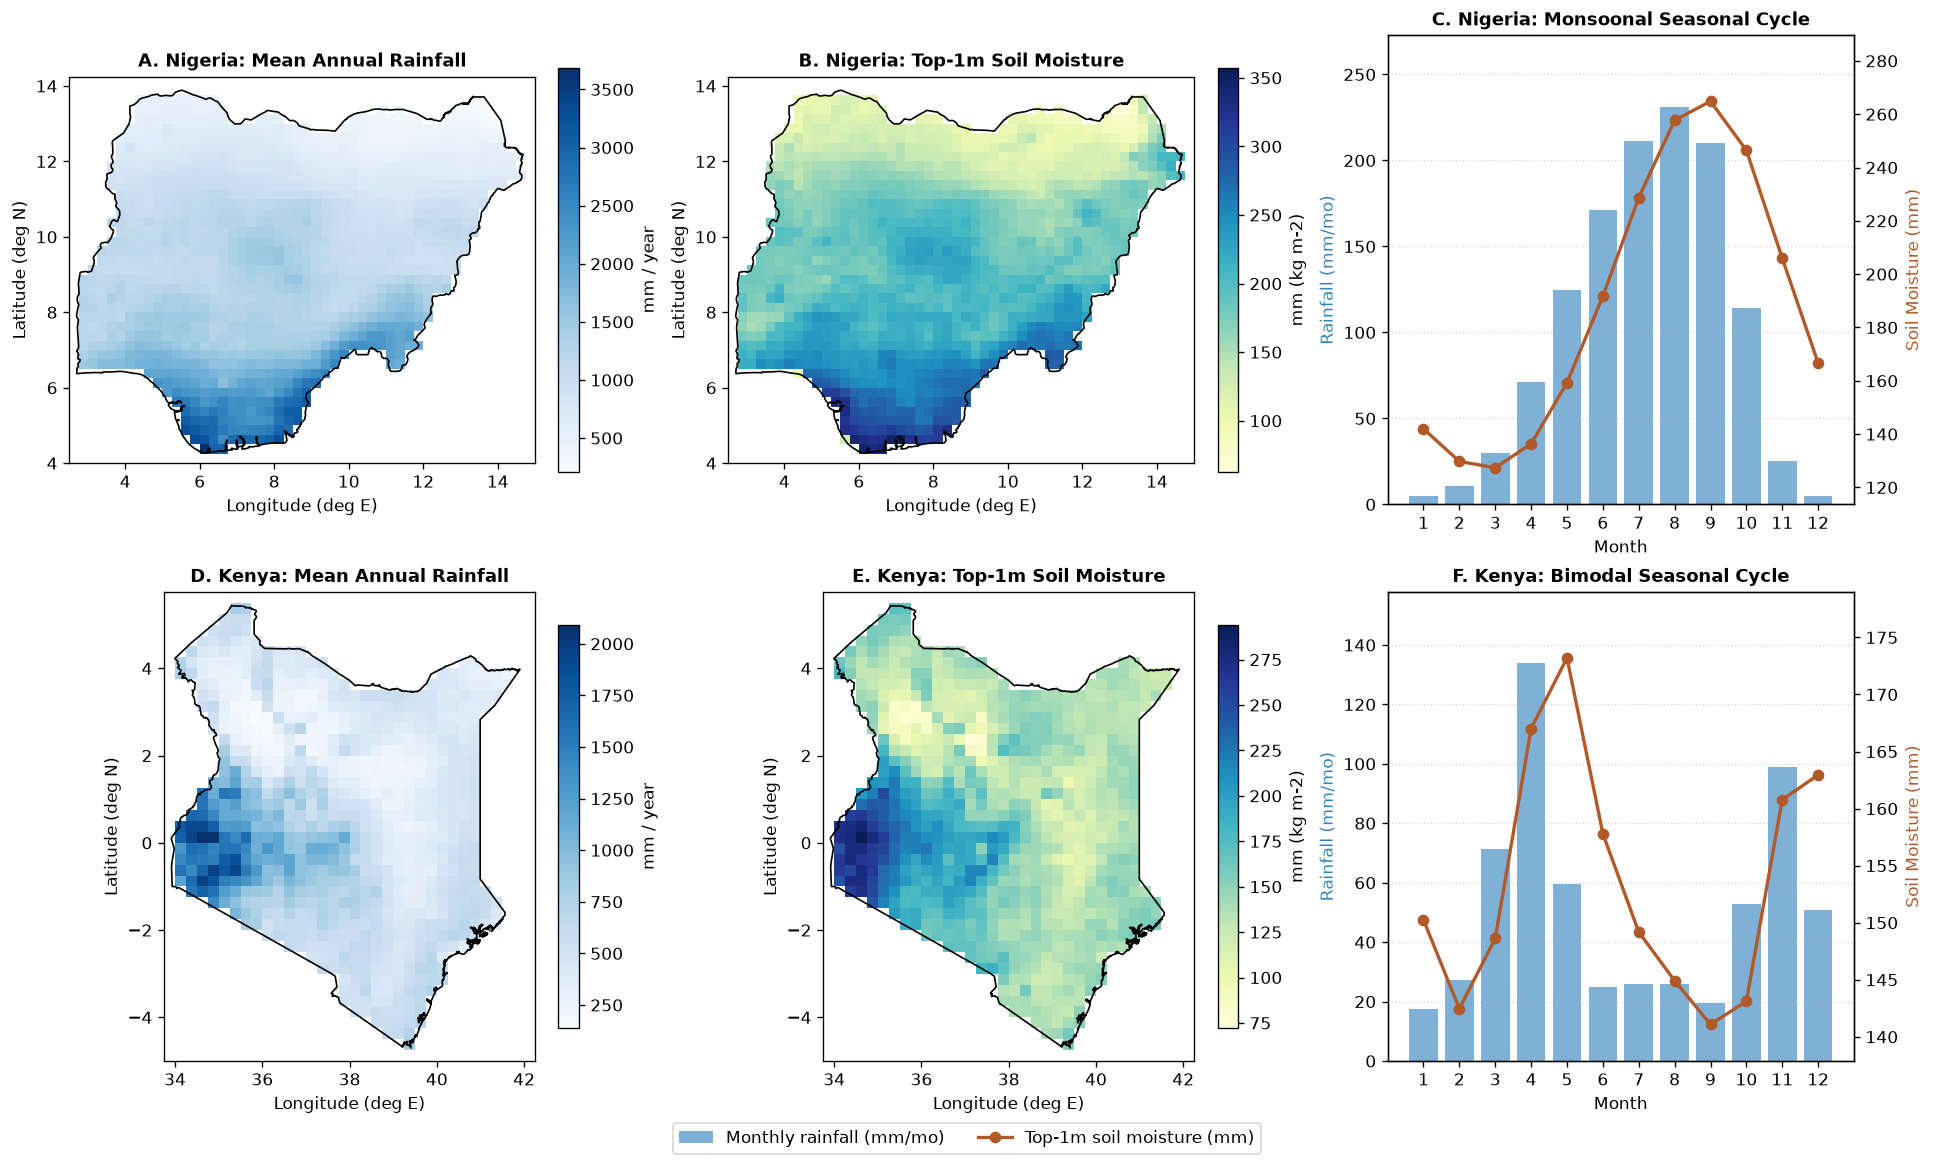

In [6]:
# Plot the 6-panel spatial climatology and seasonal cycle comparison (Figure 1)
fig, axs = plt.subplots(2, 3, figsize=(16, 9.6), layout="constrained")

# Top row: Nigeria
clim_nga["mean_annual_rain_mm"].where(clim_nga["mean_annual_rain_mm"] > 0).plot(
    ax=axs[0, 0], cmap="Blues", cbar_kwargs={"label": "mm / year", "shrink": 0.86}
)
adm0_nga.boundary.plot(ax=axs[0, 0], color="k", lw=1)
axs[0, 0].set_title("A. Nigeria: Mean Annual Rainfall", fontweight="bold", fontsize=11, pad=6)
axs[0, 0].set_xlabel("Longitude (deg E)"); axs[0, 0].set_ylabel("Latitude (deg N)")

clim_nga["mean_sm_top1m_mm"].plot(
    ax=axs[0, 1], cmap="YlGnBu", cbar_kwargs={"label": "mm (kg m-2)", "shrink": 0.86}
)
adm0_nga.boundary.plot(ax=axs[0, 1], color="k", lw=1)
axs[0, 1].set_title("B. Nigeria: Top-1m Soil Moisture", fontweight="bold", fontsize=11, pad=6)
axs[0, 1].set_xlabel("Longitude (deg E)"); axs[0, 1].set_ylabel("Latitude (deg N)")

axs[0, 2].bar(mon_nga_rain.index, mon_nga_rain.values, color="#3182bd", alpha=0.62, label="Monthly rainfall (mm/mo)")
axs[0, 2].set_ylim(0, float(mon_nga_rain.max()) * 1.18)
ax0_r = axs[0, 2].twinx()
ax0_r.plot(mon_nga_sm.index, mon_nga_sm.values, "o-", color="#b15928", lw=2, label="Top-1m soil moisture (mm)")
s_span0 = float(mon_nga_sm.max() - mon_nga_sm.min())
ax0_r.set_ylim(float(mon_nga_sm.min()) - 0.1 * s_span0, float(mon_nga_sm.max()) + 0.18 * s_span0)
axs[0, 2].set_title("C. Nigeria: Monsoonal Seasonal Cycle", fontweight="bold", fontsize=11, pad=6)
axs[0, 2].set_xlabel("Month"); axs[0, 2].set_ylabel("Rainfall (mm/mo)", color="#3182bd")
ax0_r.set_ylabel("Soil Moisture (mm)", color="#b15928")
axs[0, 2].set_xticks(range(1, 13)); axs[0, 2].grid(axis="y", ls=":", alpha=0.5)

# Bottom row: Kenya
clim_ken["mean_annual_rain_mm"].where(clim_ken["mean_annual_rain_mm"] > 0).plot(
    ax=axs[1, 0], cmap="Blues", cbar_kwargs={"label": "mm / year", "shrink": 0.86}
)
adm0_ken.boundary.plot(ax=axs[1, 0], color="k", lw=1)
axs[1, 0].set_title("D. Kenya: Mean Annual Rainfall", fontweight="bold", fontsize=11, pad=6)
axs[1, 0].set_xlabel("Longitude (deg E)"); axs[1, 0].set_ylabel("Latitude (deg N)")

clim_ken["mean_sm_top1m_mm"].plot(
    ax=axs[1, 1], cmap="YlGnBu", cbar_kwargs={"label": "mm (kg m-2)", "shrink": 0.86}
)
adm0_ken.boundary.plot(ax=axs[1, 1], color="k", lw=1)
axs[1, 1].set_title("E. Kenya: Top-1m Soil Moisture", fontweight="bold", fontsize=11, pad=6)
axs[1, 1].set_xlabel("Longitude (deg E)"); axs[1, 1].set_ylabel("Latitude (deg N)")

axs[1, 2].bar(mon_ken_rain.index, mon_ken_rain.values, color="#3182bd", alpha=0.62, label="Monthly rainfall (mm/mo)")
axs[1, 2].set_ylim(0, float(mon_ken_rain.max()) * 1.18)
ax1_r = axs[1, 2].twinx()
ax1_r.plot(mon_ken_sm.index, mon_ken_sm.values, "o-", color="#b15928", lw=2, label="Top-1m soil moisture (mm)")
s_span1 = float(mon_ken_sm.max() - mon_ken_sm.min())
ax1_r.set_ylim(float(mon_ken_sm.min()) - 0.1 * s_span1, float(mon_ken_sm.max()) + 0.18 * s_span1)
axs[1, 2].set_title("F. Kenya: Bimodal Seasonal Cycle", fontweight="bold", fontsize=11, pad=6)
axs[1, 2].set_xlabel("Month"); axs[1, 2].set_ylabel("Rainfall (mm/mo)", color="#3182bd")
ax1_r.set_ylabel("Soil Moisture (mm)", color="#b15928")
axs[1, 2].set_xticks(range(1, 13)); axs[1, 2].grid(axis="y", ls=":", alpha=0.5)

h_b, l_b = axs[0, 2].get_legend_handles_labels()
h_l, l_l = ax0_r.get_legend_handles_labels()
fig.legend(h_b + h_l, l_b + l_l, loc="outside lower center", ncol=2, frameon=True, fontsize=10)
plt.show()

<div class="nb-body">

<div class="nb-caption">Figure 1: Spatial climatology (2001-2025 mean annual rainfall and top-1 m soil moisture) and monthly seasonal cycles for Nigeria (panels A-C) and Kenya (panels D-F) derived from EOCIS 0.25-degree data.</div>

### Interpretation of Climatology and Seasonal Cycles

As shown in Table 2 and Figure 1, the two study countries have very different water patterns. In Nigeria (Figure 1, panels A and B), annual rainfall and soil moisture follow a strong north-to-south gradient, rising from dry Sahel conditions in the far north to more than 3,000 mm per year in the Niger Delta. The monthly cycle in Figure 1 (panel C) shows a single monsoon peak where rainfall reaches its highest level in August (231.0 mm), while top-1 m soil moisture peaks one month later in September (263.8 mm). This one-month lag happens because the soil column acts like a sponge that continues storing water until the end of the wet season.

In Kenya (Figure 1, panels D and E), wetness is concentrated in the western highlands near Lake Victoria and along the central rift, while the eastern and northern plains remain semi-arid. Figure 1 (panel F) shows two separate rainy seasons: the Long Rains from March to May (peaking in April at 133.6 mm) and the Short Rains from October to December (peaking in November at 98.7 mm). In both seasons, soil moisture peaks right after the heaviest rainfall (May and December), marking the periods when the ground is most saturated and any additional storms quickly turn into surface runoff.

</div>

<div class="nb-body">

### 5.2 Sub-Pixel Land Cover and Asset Exposure

To understand why a single 0.25-degree pixel value can be misleading for local flood warning, we zoom into one 0.25-degree grid cell covering Garissa town and the Tana River in eastern Kenya. First, we search the EODH CEDA catalogue for the 10 m Copernicus Land Cover tile that covers this location.

</div>

In [7]:
# Search EODH for the 10 m land cover tile intersecting Garissa
clms_items = list(
    client.search(
        collections=["clms-lcm-global-10m-yearly-v1-cog"],
        catalog_paths=[CEDA_CATALOG],
        intersects=AOI_GARISSA_POINT,
    )
)

clms_item = clms_items[0]
clms_href = clms_item.assets["data"].href
print("Matched CLMS tile ID :", clms_item.id)
print("Cloud GeoTIFF URL    :", clms_href)

Matched CLMS tile ID : LCFM_LCM-10_V100_2020_S03E039_MAP
Cloud GeoTIFF URL    : https://dap.ceda.ac.uk/neodc/copernicus_land_cover/data/2020/v1/LCFM_LCM-10_V100_2020_S03E039_MAP.tif


<div class="nb-body">

Instead of downloading the entire 3-degree by 3-degree land cover file (which is 36,000 by 36,000 pixels), we use rasterio to read only the 0.25-degree window around Garissa directly over HTTP.

</div>

In [8]:
# Stream only the 0.25-degree window for Garissa from the cloud GeoTIFF
with rasterio.open(clms_href) as src:
    win = from_bounds(*AOI_GARISSA_BBOX, src.transform)
    lc = src.read(1, window=win)

print("Streamed window shape (rows, cols):", lc.shape)
print("Total 10 m pixels inside this single 0.25-degree cell:", f"{lc.size:,}")

Streamed window shape (rows, cols): (3000, 3000)
Total 10 m pixels inside this single 0.25-degree cell: 9,000,000


<div class="nb-body">

Next, we count how many 10 m pixels belong to each land cover type and convert the pixel counts into square kilometres (since each 10 m by 10 m pixel equals 100 sq m, or 0.0001 sq km). The results are presented in Table 3.

</div>

In [9]:
# Define the Copernicus land cover classes, plot colours, and relative exposure weights
CLASS_MAP = {
    10: ("Tree cover", "#006400", 0.0),
    20: ("Shrubland", "#ffbb22", 0.0),
    30: ("Grassland", "#ffff4c", 0.05),
    40: ("Cropland", "#f096ff", 0.70),
    50: ("Built-up / Urban", "#fa0000", 1.00),
    80: ("Permanent water", "#0064c8", 0.0),
    90: ("Herbaceous wetland", "#0096a0", 0.30),
    100: ("Moss / lichen", "#fae6a0", 0.0),
}

total_px = lc.size
stats = []
for code, (label, color, vuln_weight) in CLASS_MAP.items():
    cnt = int(np.sum(lc == code))
    if cnt > 0:
        stats.append({
            "code": code,
            "label": label,
            "color": color,
            "vuln_weight": vuln_weight,
            "area_km2": (cnt * 100) / 1e6,
            "share_pct": (cnt / total_px) * 100,
        })

df_stats = pd.DataFrame(stats).sort_values("area_km2", ascending=False)
df_table3 = df_stats[["code", "label", "area_km2", "share_pct", "vuln_weight"]].rename(columns={
    "code": "Class Code",
    "label": "Land Cover Class",
    "area_km2": "Area (sq km)",
    "share_pct": "Share of Cell (%)",
    "vuln_weight": "Exposure Weight",
}).round(2)

display(HTML('<div class="nb-caption">Table 3: Sub-pixel land cover distribution and exposure weights within the 0.25-degree Garissa grid cell from CLMS 10 m data.</div>'))
display(df_table3)

,Class Code,Land Cover Class,Area (sq km),Share of Cell (%),Exposure Weight
1,20,Shrubland,604.74,67.19,0.00
2,30,Grassland,110.65,12.29,0.05
0,10,Tree cover,78.12,8.68,0.00
6,90,Herbaceous wetland,44.68,4.96,0.30
5,80,Permanent water,40.32,4.48,0.00
3,40,Cropland,9.81,1.09,0.70
7,100,Moss / lichen,9.54,1.06,0.00
4,50,Built-up / Urban,2.15,0.24,1.00


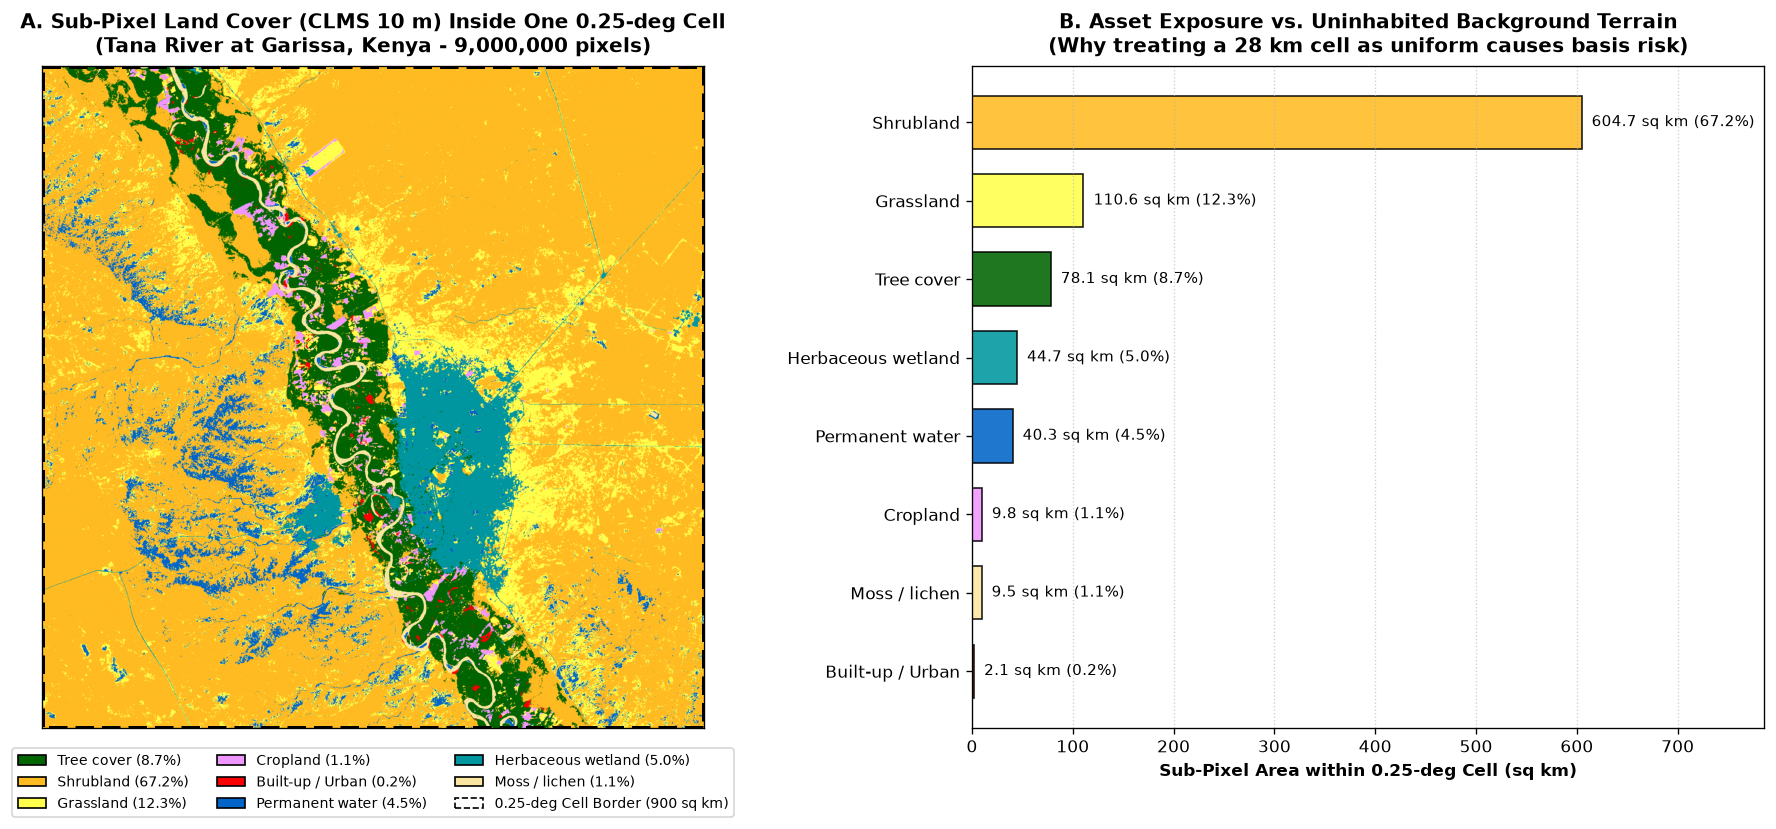

In [10]:
# Map the 10 m land cover classes and plot the area breakdown (Figure 2)
unique_codes = [s["code"] for s in stats]
code_to_idx = {c: i for i, c in enumerate(unique_codes)}
indexed_lc = np.zeros_like(lc, dtype=int)
for c in unique_codes:
    indexed_lc[lc == c] = code_to_idx[c]

fig, axs = plt.subplots(1, 2, figsize=(15, 6.8), gridspec_kw={"width_ratios": [1.1, 1.1]}, layout="constrained")
axs[0].imshow(indexed_lc, cmap=ListedColormap([s["color"] for s in stats]))
h, w = lc.shape
axs[0].add_patch(Rectangle((2, 2), w - 4, h - 4, lw=3, edgecolor="black", facecolor="none", ls="--"))
axs[0].set_title("A. Sub-Pixel Land Cover (CLMS 10 m) Inside One 0.25-deg Cell\n(Tana River at Garissa, Kenya - 9,000,000 pixels)", fontweight="bold", pad=8)
axs[0].set_xticks([]); axs[0].set_yticks([])

legend_els = [Patch(facecolor=s["color"], edgecolor="k", label=f"{s['label']} ({s['share_pct']:.1f}%)") for s in stats]
legend_els.append(Patch(facecolor="none", edgecolor="black", ls="--", label="0.25-deg Cell Border (900 sq km)"))
axs[0].legend(handles=legend_els, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=8.5, frameon=True)

bars = axs[1].barh(df_stats["label"], df_stats["area_km2"], color=df_stats["color"], edgecolor="k", alpha=0.88, height=0.68)
axs[1].invert_yaxis()
axs[1].set_xlabel("Sub-Pixel Area within 0.25-deg Cell (sq km)", fontweight="bold")
axs[1].set_title("B. Asset Exposure vs. Uninhabited Background Terrain\n(Why treating a 28 km cell as uniform causes basis risk)", fontweight="bold", pad=8)
for bar in bars:
    width = bar.get_width()
    pct = (width / df_stats["area_km2"].sum()) * 100
    axs[1].text(width + 10, bar.get_y() + bar.get_height() / 2, f"{width:.1f} sq km ({pct:.1f}%)", va="center", fontsize=8.8)
axs[1].set_xlim(0, max(df_stats["area_km2"]) * 1.30)
axs[1].grid(axis="x", ls=":", alpha=0.6)

plt.show()

<div class="nb-body">

<div class="nb-caption">Figure 2: Sub-pixel land cover map at 10 m resolution (panel A) and area breakdown by land cover class (panel B) inside a single 0.25-degree grid cell at Garissa, Kenya.</div>

### Interpretation of Sub-Pixel Exposure

Table 3 and Figure 2 clearly illustrate why taking a single average number for a 28 km grid cell is problematic. Inside this one cell (9,000,000 pixels at 10 m resolution), 67.19% of the land (604.74 sq km) is dry, uninhabited shrubland and 12.29% (110.65 sq km) is open grassland. In contrast, the places where flood damage actually harms people and livelihoods make up only a tiny fraction of the box: agricultural cropland covers just 1.09% (9.81 sq km, shown in pink along the riverbanks in Figure 2, panel A), and built-up urban settlement (Garissa town, shown in red) covers only 0.24% (2.15 sq km).

When a river overflows, the floodwater stays inside the narrow green and cyan river corridor running through the middle of Figure 2 (panel A). By combining the 10 m land cover map with the 0.25-degree soil moisture model, disaster planners can weight the warning trigger toward the 1.33% of land containing farms and homes rather than the 67.19% covered by empty bushland.

</div>

<div class="nb-body">

### 5.3 High-Resolution Flood Verification with Sentinel-2

During April and May 2024, heavy Long Rains caused severe flooding along the Tana River in Kenya. To check whether our 0.25-degree soil moisture anomaly gave advance warning of real flooding on the ground, we retrieve two cloud-free Sentinel-2 Level-2A scenes from EODH over the exact same Garissa grid cell: one before the rains (10 March 2024) and one at the height of the flood (19 May 2024).

</div>

In [11]:
# Retrieve the dry baseline scene and peak flood scene from the EODH Element84 catalogue
it_dry = s2_l2a.get_item("S2A_T37MEV_20240310T074424_L2A")
it_flood = s2_l2a.get_item("S2A_T37MEV_20240519T074617_L2A")

print(f"Dry baseline scene : {it_dry.id} | Date: {str(it_dry.datetime)[:10]} | Cloud cover: {it_dry.properties.get('eo:cloud_cover'):.1f}%")
print(f"Flood peak scene   : {it_flood.id} | Date: {str(it_flood.datetime)[:10]} | Cloud cover: {it_flood.properties.get('eo:cloud_cover'):.1f}%")

Dry baseline scene : S2A_T37MEV_20240310T074424_L2A | Date: 2024-03-10 | Cloud cover: 16.6%
Flood peak scene   : S2A_T37MEV_20240519T074617_L2A | Date: 2024-05-19 | Cloud cover: 1.5%


<div class="nb-body">

Muddy floodwater reflects more near-infrared light than clear water, so standard water indices often miss brown river floods. To capture sediment-rich floodwater accurately, we stream the Green (10 m) and short-wave infrared SWIR16 (20 m) bands for our Garissa bounding box and calculate the Modified Normalized Difference Water Index (MNDWI = (Green - SWIR16) / (Green + SWIR16)).

</div>

In [12]:
def stream_s2_mndwi(item, bounds_4326):
    # Open the true-colour visual image and crop to the Garissa bounding box
    with rasterio.open(item.assets["visual"].href) as src_vis:
        b_utm = transform_bounds("EPSG:4326", src_vis.crs, *bounds_4326)
        win = from_bounds(*b_utm, src_vis.transform)
        rgb = np.clip(src_vis.read(window=win).transpose(1, 2, 0) / 255.0, 0, 1)

    # Read the 10 m Green band and 20 m SWIR16 band for the same window
    with rasterio.open(item.assets["green"].href) as src_g:
        green = src_g.read(1, window=win).astype(float)
    with rasterio.open(item.assets["swir16"].href) as src_swir:
        win_swir = from_bounds(*b_utm, src_swir.transform)
        swir = src_swir.read(1, window=win_swir, out_shape=green.shape).astype(float)

    # Compute MNDWI
    denom = green + swir
    mndwi = np.where(denom > 0, (green - swir) / denom, -1.0)
    return rgb, mndwi

rgb_dry, mndwi_dry = stream_s2_mndwi(it_dry, AOI_GARISSA_BBOX)
rgb_flood, mndwi_flood = stream_s2_mndwi(it_flood, AOI_GARISSA_BBOX)
print("Finished streaming Sentinel-2 windows. Image shape:", rgb_flood.shape)

Finished streaming Sentinel-2 windows. Image shape: (2764, 2782, 3)


<div class="nb-body">

Now we compare the water mask on 19 May 2024 against the dry-season channel on 10 March 2024 to measure how many square kilometres of land were newly submerged.

</div>

In [13]:
# Identify permanent river water (dry season) and expanded floodwater (May 2024)
water_dry = mndwi_dry > 0.0
water_flood = mndwi_flood > -0.05
new_inundation = water_flood & (~water_dry)

# Convert 10 m pixel counts to square kilometres
perm_water_km2 = (int(np.sum(water_dry)) * 100) / 1e6
inundation_km2 = (int(np.sum(new_inundation)) * 100) / 1e6
total_water_km2 = (int(np.sum(water_flood)) * 100) / 1e6
cell_area_km2 = (water_flood.size * 100) / 1e6

print(f"Permanent river channel (10 Mar 2024) : {perm_water_km2:.1f} sq km")
print(f"Newly submerged floodplain (19 May)   : {inundation_km2:.1f} sq km")
print(f"Total flooded corridor (19 May 2024)  : {total_water_km2:.1f} sq km ({total_water_km2 / cell_area_km2 * 100:.1f}% of the 0.25-deg cell)")

Permanent river channel (10 Mar 2024) : 4.1 sq km
Newly submerged floodplain (19 May)   : 16.3 sq km
Total flooded corridor (19 May 2024)  : 20.4 sq km (2.6% of the 0.25-deg cell)


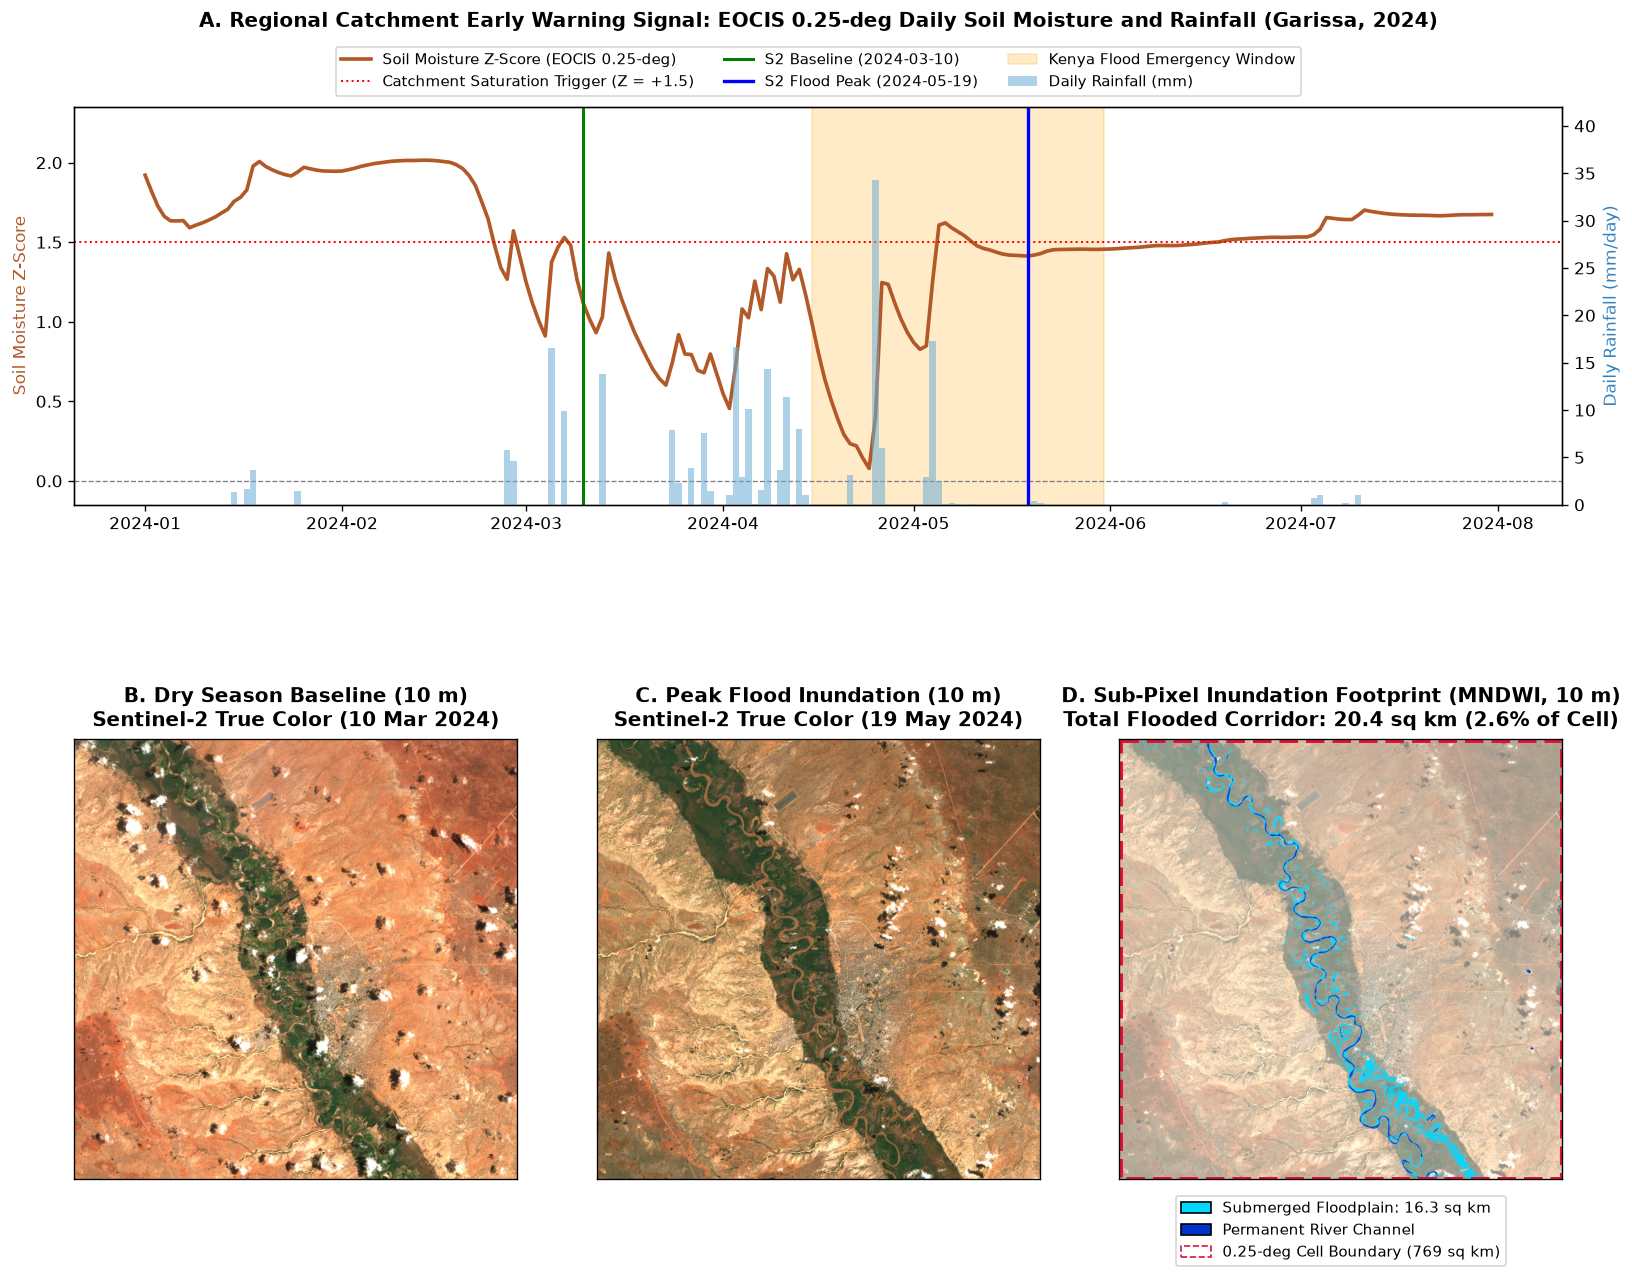

In [14]:
# Plot the 4-panel multi-scale flood verification chart (Figure 3)
df_gar = df_ts[(df_ts.region == "garissa_cell") & (df_ts.time >= "2024-01-01") & (df_ts.time <= "2024-07-31")].set_index("time")

fig = plt.figure(figsize=(16, 12.2))
gs = fig.add_gridspec(2, 3, height_ratios=[1.05, 1.45], hspace=0.38, wspace=0.18)

ax_ts = fig.add_subplot(gs[0, :])
ax_rain = ax_ts.twinx()
ax_rain.bar(df_gar.index, df_gar["rain_mm"], width=1.0, color="#6baed6", alpha=0.55, label="Daily Rainfall (mm)")
ax_ts.plot(df_gar.index, df_gar["sm_z"], color="#b15928", lw=2.2, label="Soil Moisture Z-Score (EOCIS 0.25-deg)")
ax_ts.axhline(0, color="gray", lw=0.8, ls="--")
ax_ts.axhline(1.5, color="red", lw=1.2, ls=":", label="Catchment Saturation Trigger (Z = +1.5)")
ax_ts.axvline(pd.Timestamp(S2_DRY_DATE), color="green", lw=1.8, label=f"S2 Baseline ({S2_DRY_DATE})")
ax_ts.axvline(pd.Timestamp(S2_FLOOD_DATE), color="blue", lw=2.0, label=f"S2 Flood Peak ({S2_FLOOD_DATE})")
ax_ts.axvspan(pd.Timestamp("2024-04-15"), pd.Timestamp("2024-05-31"), color="orange", alpha=0.22, label="Kenya Flood Emergency Window")
ax_ts.set_ylim(-0.15, 2.35)
ax_rain.set_ylim(0, 42)
ax_ts.set_ylabel("Soil Moisture Z-Score", color="#b15928")
ax_rain.set_ylabel("Daily Rainfall (mm/day)", color="#3182bd")
ax_ts.set_title("A. Regional Catchment Early Warning Signal: EOCIS 0.25-deg Daily Soil Moisture and Rainfall (Garissa, 2024)", fontweight="bold", pad=48)
h1, l1 = ax_ts.get_legend_handles_labels(); h2, l2 = ax_rain.get_legend_handles_labels()
ax_ts.legend(h1 + h2, l1 + l2, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, fontsize=8.8, frameon=True)

ax_b = fig.add_subplot(gs[1, 0])
ax_b.imshow(rgb_dry); ax_b.set_title("B. Dry Season Baseline (10 m)\nSentinel-2 True Color (10 Mar 2024)", fontweight="bold", pad=8)
ax_b.set_xticks([]); ax_b.set_yticks([])

ax_c = fig.add_subplot(gs[1, 1])
ax_c.imshow(rgb_flood); ax_c.set_title("C. Peak Flood Inundation (10 m)\nSentinel-2 True Color (19 May 2024)", fontweight="bold", pad=8)
ax_c.set_xticks([]); ax_c.set_yticks([])

ax_d = fig.add_subplot(gs[1, 2])
ax_d.imshow(rgb_flood, alpha=0.55)
overlay = np.zeros((*water_flood.shape, 4))
overlay[water_dry] = [0.0, 0.2, 0.8, 0.9]
overlay[new_inundation] = [0.0, 0.85, 1.0, 0.95]
ax_d.imshow(overlay)
h, w = water_flood.shape
ax_d.add_patch(Rectangle((2, 2), w - 4, h - 4, lw=3, edgecolor="crimson", facecolor="none", ls="--"))
ax_d.legend(handles=[
    Patch(facecolor=[0.0, 0.85, 1.0], edgecolor="k", label=f"Submerged Floodplain: {inundation_km2:.1f} sq km"),
    Patch(facecolor=[0.0, 0.2, 0.8], edgecolor="k", label="Permanent River Channel"),
    Patch(facecolor="none", edgecolor="crimson", ls="--", label="0.25-deg Cell Boundary (769 sq km)")
], loc="upper center", bbox_to_anchor=(0.5, -0.02), fontsize=8.8, frameon=True, ncol=1)
ax_d.set_title(f"D. Sub-Pixel Inundation Footprint (MNDWI, 10 m)\nTotal Flooded Corridor: {total_water_km2:.1f} sq km ({total_water_km2/cell_area_km2*100:.1f}% of Cell)", fontweight="bold", pad=8)
ax_d.set_xticks([]); ax_d.set_yticks([])

plt.show()

<div class="nb-body">

<div class="nb-caption">Figure 3: Multi-scale verification of the May 2024 Garissa flood event, showing the daily 0.25-degree EOCIS soil moisture Z-score and rainfall series (panel A), 10 m Sentinel-2 true-colour imagery before the rains on 10 March 2024 (panel B) and during peak flooding on 19 May 2024 (panel C), and the MNDWI flooded corridor footprint inside the 0.25-degree grid boundary (panel D).</div>

### Interpretation of Multi-Scale Flood Verification

Figure 3 shows how the coarse 0.25-degree climate signal and the 10 m optical satellite imagery complement each other. In Figure 3 (panel A), heavy storms in late April and early May 2024 pushed the regional soil moisture Z-score sharply above the +1.5 trigger threshold more than two weeks before the 19 May satellite overpass. This confirms that the regional soil sponge was completely full and unable to absorb further rain.

Comparing Figure 3 (panel B) and Figure 3 (panel C) shows the physical impact on the ground: the narrow Tana River channel visible in March expanded into a wide, muddy brown floodway by 19 May. As mapped in Figure 3 (panel D), the flooded river corridor expanded from 4.1 sq km of permanent river water to 20.4 sq km of total water (an additional 16.3 sq km of newly submerged floodplain). Even during this severe disaster, standing floodwater covered only 2.6% of the 769 sq km grid box, but that 2.6% fell directly inside the riparian agricultural and settlement belt identified earlier in Figure 2.

</div>

<div class="nb-body">

### 5.4 Validation Against Historical Flood Disasters

To check whether soil moisture and rainfall anomalies reliably flag floods across many years, we test our indicators against 62 historical flood events recorded by the Dartmouth Flood Observatory (DFO) across Kenya and Nigeria. For each flood event window (from 7 days before the reported start to 7 days after the end), we compare the peak indicator value during the flood against the exact same calendar window in all other years (2000-2025). A percentile score of 0.50 means the indicator is no better than random chance, while a score near 1.00 means the flood window was wetter than almost every other year on record. Table 4 shows the validation results for major flood disasters.

</div>

In [15]:
# Load the event-level and summary validation tables
df_val_events = pd.read_csv("docs/trigger_validation_events.csv", parse_dates=["start", "end"])
df_val_summary = pd.read_csv("docs/trigger_validation_summary.csv")

# Filter to major flood disasters for Table 4
df_table4 = df_val_summary[
    (df_val_summary.group == "major events") &
    (df_val_summary.country.isin(["kenya", "nigeria"])) &
    (df_val_summary["index"].isin(["frac_compound", "sm_z_mean", "rain_z7_mean", "rain_30d_z_mean"]))
].copy()

index_names = {
    "frac_compound": "Compound Trigger (Area Share)",
    "sm_z_mean": "Soil Moisture Z-Score (Mean)",
    "rain_z7_mean": "7-Day Rainfall Z-Score (Mean)",
    "rain_30d_z_mean": "30-Day Rainfall Z-Score (Mean)",
}
df_table4["country"] = df_table4["country"].str.title()
df_table4["index"] = df_table4["index"].map(index_names)
df_table4 = df_table4[["country", "index", "n", "median_pct", "share_pct_ge_0_8", "share_pct_ge_0_5"]].rename(columns={
    "country": "Country",
    "index": "Trigger Indicator",
    "n": "Major Events (N)",
    "median_pct": "Median Percentile Rank",
    "share_pct_ge_0_8": "Share >= 80th Pct",
    "share_pct_ge_0_5": "Share >= 50th Pct",
}).round(2)

display(HTML('<div class="nb-caption">Table 4: Historical trigger validation skill across major flood events in Kenya and Nigeria (2000-2025 baseline).</div>'))
display(df_table4)

,Country,Trigger Indicator,Major Events (N),Median Percentile Rank,Share >= 80th Pct,Share >= 50th Pct
0,Nigeria,Compound Trigger (Area Share),10,0.44,0.10,0.50
1,Nigeria,Soil Moisture Z-Score (Mean),10,0.56,0.10,0.60
2,Nigeria,7-Day Rainfall Z-Score (Mean),10,0.42,0.20,0.30
3,Nigeria,30-Day Rainfall Z-Score (Mean),10,0.50,0.20,0.50
12,Kenya,Compound Trigger (Area Share),17,0.72,0.47,0.82
13,Kenya,Soil Moisture Z-Score (Mean),17,0.76,0.41,0.76
14,Kenya,7-Day Rainfall Z-Score (Mean),17,0.76,0.47,0.82
15,Kenya,30-Day Rainfall Z-Score (Mean),17,0.80,0.59,0.82


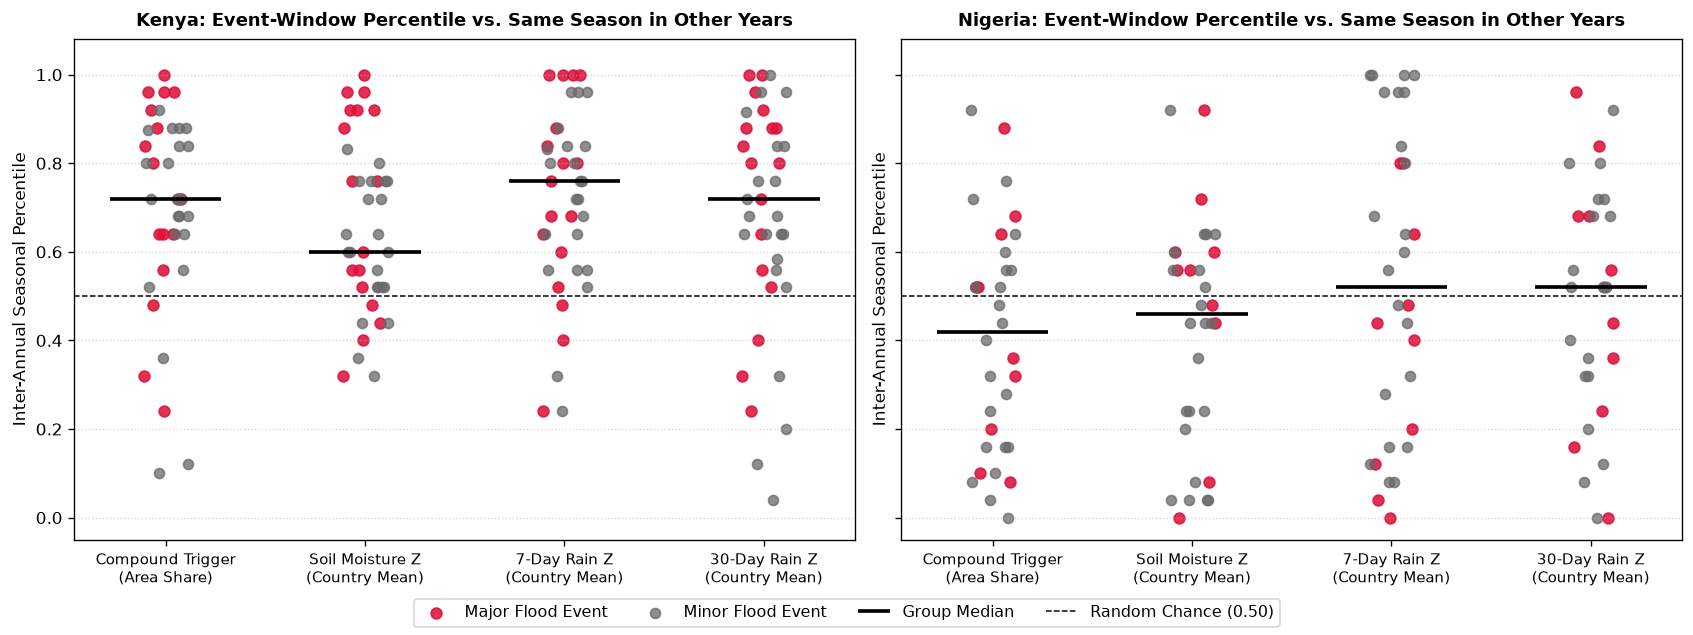

In [16]:
# Plot the distribution of event percentile scores for Kenya and Nigeria (Figure 4)
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True, layout="constrained")
cols = ["pct_frac_compound", "pct_sm_z_mean", "pct_rain_z7_mean", "pct_rain_30d_z_mean"]
labels = ["Compound Trigger\n(Area Share)", "Soil Moisture Z\n(Country Mean)", "7-Day Rain Z\n(Country Mean)", "30-Day Rain Z\n(Country Mean)"]

for ax, c in zip(axs, ["kenya", "nigeria"]):
    sub = df_val_events[df_val_events.country == c]
    for i, p in enumerate(cols):
        v = sub[sub[p].notnull()]
        jitter = np.random.default_rng(42).uniform(-0.12, 0.12, len(v))
        maj = v[v.major]
        minr = v[~v.major]
        ax.scatter(np.full(len(maj), i) + jitter[v.major.values], maj[p], c="crimson", s=42, alpha=0.88,
                   label="Major Flood Event" if i == 0 else None)
        ax.scatter(np.full(len(minr), i) + jitter[~v.major.values], minr[p], c="dimgray", s=36, alpha=0.75,
                   label="Minor Flood Event" if i == 0 else None)
        ax.hlines(v[p].median(), i - 0.28, i + 0.28, color="k", lw=2.2,
                  label="Group Median" if i == 0 else None)
    ax.axhline(0.5, ls="--", color="k", lw=0.9, label="Random Chance (0.50)")
    ax.set_ylim(-0.05, 1.08)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(labels, fontsize=9)
    ax.set_title(f"{c.title()}: Event-Window Percentile vs. Same Season in Other Years", fontweight="bold", fontsize=11, pad=8)
    ax.set_ylabel("Inter-Annual Seasonal Percentile")
    ax.grid(axis="y", ls=":", alpha=0.5)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="outside lower center", ncol=4, frameon=True, fontsize=9.5)
plt.show()

<div class="nb-body">

<div class="nb-caption">Figure 4: Inter-annual percentile rank of flood event windows compared to the same calendar season in all other baseline years for Kenya (left) and Nigeria (right). Red dots represent major floods, grey dots represent minor floods, solid black bars mark the group median, and the dashed line at 0.50 represents random chance.</div>

### Interpretation of Historical Validation

The comparison in Table 4 and Figure 4 reveals an important hydrological difference between the two countries. In Kenya (Figure 4, left panel), all four indicators perform well above random chance: for major flood events (Table 4), the median percentile rank is between 0.72 and 0.80, and 76% to 82% of major floods score above the 50th percentile. This happens because Kenyan floods are mostly driven by heavy rain falling directly onto saturated local catchments.

In Nigeria (Figure 4, right panel), the country-average percentile scores sit close to 0.42 to 0.56 (Table 4). While extreme national monsoon seasons such as 2012 and 2022 do register strong soil moisture spikes (above the 88th percentile), many smaller or mid-season floods in Nigeria occur along the lower Niger and Benue rivers when water flows downstream from upstream countries (such as Guinea, Mali, Niger, and Cameroon's Lagdo Dam releases) even if local rainfall inside Nigeria is near normal. Recognising this limitation is vital for risk modelling: local soil moisture triggers are directly effective for rainfall-driven catchments like Kenya, whereas large lowland river corridors in Nigeria also require upstream river gauge or discharge routing inputs.

</div>

<div class="nb-body">

### 5.5 Operational Decision Matrix

To turn these findings into a practical tool for disaster response agencies and parametric insurers, Table 5 outlines a three-tier operational protocol that combines all three EODH datasets.

<div class="nb-caption">Table 5: Three-tier operational flood early-warning and parametric trigger protocol combining EOCIS 0.25-degree soil moisture, CLMS 10 m land cover, and Sentinel-2 10 m water mapping.</div>

| Alert Tier | Stage 1: Regional Soil Sponge (EOCIS 0.25 deg) | Stage 2: Asset Exposure Filter (CLMS 10 m) | Stage 3: Flood Confirmation (Sentinel-2 10 m) | Recommended Operational Action |
|---|---|---|---|---|
| Tier 1: Advisory (Yellow) | Soil moisture Z-score >= +1.0 (above 84th percentile) | Grid cell contains > 1 sq km of cropland or urban land | Start automated watch for next satellite overpass | Send early advisories to local farm officers and clear urban storm drains |
| Tier 2: Alert (Orange) | Soil moisture Z-score >= +1.5 and 7-day rain Z-score >= +1.0 | River buffer overlaps CLMS cropland (Class 40) or urban (Class 50) | Windowed MNDWI shows > 5 sq km of new floodwater | Pre-position relief supplies and issue evacuation warnings for low-lying areas |
| Tier 3: Crisis / Payout (Red) | Soil moisture Z-score >= +1.5 for 5 or more consecutive days | Confirmed water overlap on cropland or urban pixels | Newly submerged floodplain exceeds 15 sq km | Release parametric insurance payouts and deploy emergency response teams |

### Interpretation of the Decision Matrix

As summarised in Table 5, no single satellite sensor needs to do everything on its own. Stage 1 uses the coarse 0.25-degree EOCIS dataset to monitor the whole country cheaply every day. When a grid cell crosses the Stage 1 threshold, Stage 2 checks the 10 m CLMS map (Table 3 and Figure 2) to see if towns or farms actually exist inside that cell. Finally, Stage 3 streams a small 10 m Sentinel-2 window (Figure 3) to confirm physical flooding before releasing emergency funds.

</div>

<div class="nb-body">

## 6. EO Data Hub capability demonstrated

EODH functionality used: This notebook uses the pyeodh Python client to search and access two different STAC catalogues hosted on the EO Data Hub (the CEDA STAC catalogue and the Element84 Earth Search catalogue) through a single interface. It also uses HTTP range requests (windowed reading via rasterio) to stream small geographic subsets directly from Cloud-Optimized GeoTIFFs (COGs) without downloading full gigabyte-sized satellite tiles.

Why the Hub is useful for this workflow: Combining climate reanalysis data with 10 m land cover and 10 m optical imagery normally requires visiting three separate data portals with different search tools and file formats. Having all three collections indexed under the EODH STAC API allows a multi-scale workflow (28 km down to 10 m) to run cleanly inside a single notebook.

</div>

<div class="nb-body">

## 7. References and acknowledgements

1. Brocca, L., Melone, F., Moramarco, T., and Morbidelli, R. (2010). Improving runoff prediction through the assimilation of satellite-derived soil moisture. Journal of Hydrology, 385(1-4), 160-170. https://doi.org/10.1016/j.jhydrol.2010.02.018
2. Brocca, L., et al. (2017). Soil moisture for hydrological applications: Open questions and new opportunities. Water, 9(2), 140. https://doi.org/10.3390/w9020140
3. Greatrex, H., Hansen, J. W., Garvin, S., Diro, R., Blakeley, S., Le Guen, M., Rao, K. N., and Osgood, D. E. (2015). Scaling up index insurance for smallholder farmers: Recent evidence and insights. CCAFS Report No. 14, CGIAR. https://hdl.handle.net/10568/53101
4. Maidment, R. I., et al. (2017). A new, long-term daily satellite-based rainfall dataset for operational monitoring in Africa. Scientific Data, 4, 170063. https://doi.org/10.1038/sdata.2017.63
5. Wood, E. F., et al. (2011). Hyperresolution global land surface modeling: Meeting a grand challenge for science and society. Water Resources Research, 47(5), W05301. https://doi.org/10.1029/2010WR010090
6. Xu, H. (2006). Modification of normalised difference water index (NDWI) to enhance open water features in remotely sensed imagery. International Journal of Remote Sensing, 27(14), 3025-3033. https://doi.org/10.1080/01431160600589179

### Acknowledgements

The author thanks the UK Earth Observation Data Hub (EODH), the National Centre for Earth Observation (NCEO), CEDA, the TAMSAT and EOCIS teams at the University of Reading, Copernicus, and Element84 for providing open access to the datasets used in this notebook.

AI-use disclosure: In compliance with competition rules, an AI coding assistant (Antigravity) was used to assist with STAC query syntax, data-processing script structure, and figure formatting. All research questions, study-area selections, anomaly calculations, literature checks, and hydrological interpretations were conducted and verified by the author.

</div>

<div class="nb-body">

## 8. Copyright and licensing

By submitting this notebook, the author confirms that they have the right to publish the submitted material and are content for the methods and intellectual property disclosed in the submission to be publicly accessible under the licences stated below.

### Code

Unless a code cell or third-party component is explicitly identified otherwise, original code written for this notebook is licensed under the MIT License, a copy of which is available in the Competition repository.

Copyright: (c) 2026 Flawiya S. More

### Notebook text, original figures and other original non-code content

Unless otherwise stated, original non-code content created by the author for this notebook is licensed under the Creative Commons Attribution 4.0 International (CC BY 4.0) licence. This includes original explanatory text, diagrams, tables and figures where the author owns the necessary rights. Attribution should identify the author, notebook title, year, and licence.

### Data and third-party material

Entrants must ensure that any data they contribute themselves is appropriately licensed for public access and reuse.

### Third-party copyright notices

* EOCIS Soil Moisture Africa v2.3.1: (c) TAMSAT / University of Reading / UK EOCIS (Open Access).
* Copernicus Land Monitoring Service (CLMS) 10 m Land Cover (2020): (c) European Union, Copernicus Land Monitoring Service 2020.
* Copernicus Sentinel-2 Level-2A: (c) European Space Agency (ESA) / Copernicus (Open Access, indexed via Element84 Earth Search on EODH).
* geoBoundaries Administrative Boundaries: CC BY 4.0 / Public Domain (Runfola et al., 2020).
* Dartmouth Flood Observatory (DFO) Global Active Archive of Large Flood Events: Brakenridge, G. R., CC BY 4.0 via Humanitarian Data Exchange (HDX).

### Author declaration

By submitting this notebook, the author confirms that, to the best of their knowledge:

* they have permission to publish all material included in the submission;
* the licensing and attribution information supplied is accurate;
* no confidential information, credentials or material that cannot lawfully be made public has been included;
* third-party licence conditions have been followed, including conditions applying to derived works; and
* they understand that the submitted notebook, its methods and the intellectual property intentionally disclosed within it will be publicly accessible.

</div>

<div style="margin-top:38px;padding:26px 20px 12px 20px;border-top:2px solid #dbe2ee;text-align:center;font-family:Arial,Helvetica,sans-serif;color:#263d73;">
<p style="font-size:15px;text-align:center;">EARTH OBSERVATION DATA HUB</p>
<p style="margin-top:12px;font-size:14px;text-align:center;">Notebook created as part of the EODH Community Notebook Competition 2026.</p>
</div>